# 01 · Exploratory data analysis
Load raw SECOM data; class balance, missing data, constant sensors, value ranges, and fail rate over time.
Saves `figures/missing_per_sensor.png` and `figures/fails_over_time.png`.

In [39]:
import pandas as pd


X = pd.read_csv("../data/secom.data", sep=r"\s+", header=None)
labels = pd.read_csv("../data/secom_labels.data", sep=r"\s+", header=None,
                     names=["label", "date", "time"])
labels["timestamp"] = pd.to_datetime(labels["date"] + " " + labels["time"],
                                     dayfirst=True)
y = (labels["label"] == 1).astype(int)

print("X shape:", X.shape)
print(y.value_counts())
print(labels["timestamp"].min(), "to", labels["timestamp"].max())
print("Total missing values:", X.isna().sum().sum())

X shape: (1567, 590)
label
0    1463
1     104
Name: count, dtype: int64
NaT to NaT
Total missing values: 41951


In [40]:
labels = pd.read_csv("../data/secom_labels.data", sep=r"\s+", header=None,
                     names=["label", "timestamp"])
labels["timestamp"] = pd.to_datetime(labels["timestamp"], dayfirst=True)
y = (labels["label"] == 1).astype(int)

print(labels.head())
print("Missing timestamps:", labels["timestamp"].isna().sum())

   label           timestamp
0     -1 2008-07-19 11:55:00
1     -1 2008-07-19 12:32:00
2      1 2008-07-19 13:17:00
3     -1 2008-07-19 14:43:00
4     -1 2008-07-19 15:22:00
Missing timestamps: 0


In [41]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
FIG = "../figures/"

In [42]:
fail_rate = y.mean()
print(f"Fails: {y.sum()} / {len(y)}  ({fail_rate:.1%})")
print(f"Accuracy of always predicting 'pass': {1 - fail_rate:.1%}")

Fails: 104 / 1567  (6.6%)
Accuracy of always predicting 'pass': 93.4%


Sensors with any missing: 538
Sensors > 20% missing: 32
Sensors > 50% missing: 28
Overall missing: 4.5%


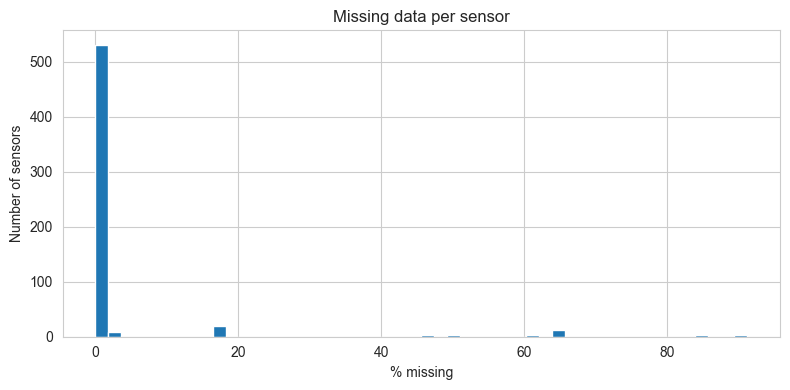

In [43]:
missing_pct = X.isna().mean() * 100

print("Sensors with any missing:", (missing_pct > 0).sum())
print("Sensors > 20% missing:", (missing_pct > 20).sum())
print("Sensors > 50% missing:", (missing_pct > 50).sum())
print("Overall missing:", f"{X.isna().values.mean():.1%}")

plt.figure(figsize=(8, 4))
plt.hist(missing_pct, bins=50)
plt.xlabel("% missing")
plt.ylabel("Number of sensors")
plt.title("Missing data per sensor")
plt.tight_layout()
plt.savefig(FIG + "missing_per_sensor.png", dpi=150)
plt.show()

In [44]:
n_unique = X.nunique(dropna=True)
constant = n_unique[n_unique <= 1].index
print("Constant sensors:", len(constant))

Constant sensors: 116


In [45]:
stds = X.std()
print("Std range:", stds[stds > 0].min(), "to", stds.max())
print(X.describe().T[["mean", "std", "min", "max"]].sample(10, random_state=0))

Std range: 0.00010440797375672332 to 6553.569317232143
            mean         std       min        max
225  1041.056588  433.170076  168.7998  3601.2998
14      9.005371    2.796596    2.2493    19.5465
85      0.112783    0.002928    0.1053     0.1184
418   320.259235  287.704482    0.0000   999.3160
132     2.318545    0.053181    2.1911     2.4723
213     0.060346    0.053030    0.0037     1.2837
186     0.000000    0.000000    0.0000     0.0000
340    14.673507  261.738451    0.0131  5043.8789
122     3.898390    0.904120    1.6710     6.8890
394     0.000000    0.000000    0.0000     0.0000


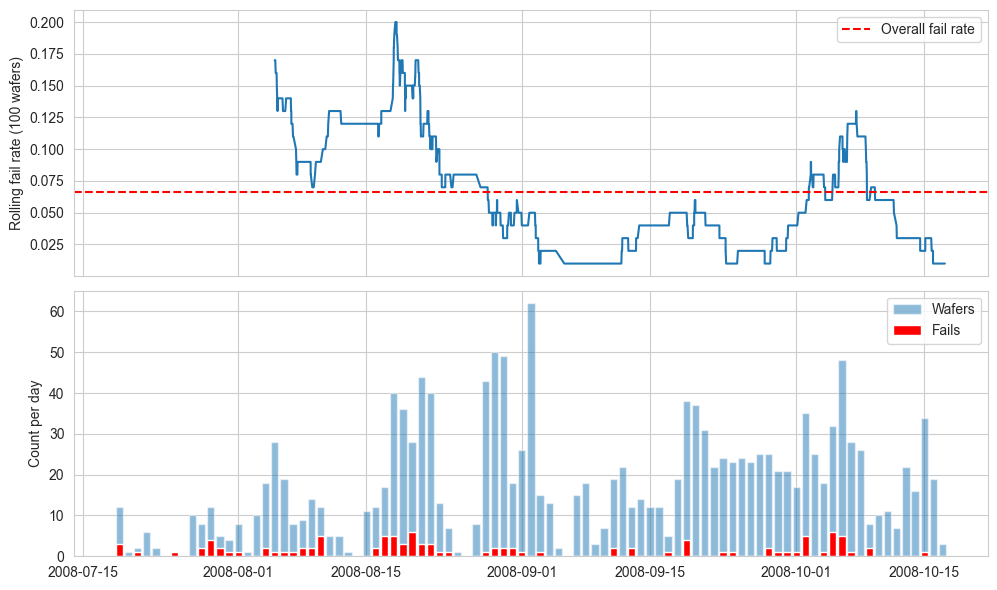

In [46]:
df_time = pd.DataFrame({"timestamp": labels["timestamp"], "fail": y})
df_time = df_time.sort_values("timestamp").reset_index(drop=True)

# Rolling fail rate over 100 consecutive wafers
df_time["rolling_fail_rate"] = df_time["fail"].rolling(100).mean()

fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax[0].plot(df_time["timestamp"], df_time["rolling_fail_rate"])
ax[0].axhline(fail_rate, color="red", ls="--", label="Overall fail rate")
ax[0].set_ylabel("Rolling fail rate (100 wafers)")
ax[0].legend()

daily = df_time.set_index("timestamp").resample("D")["fail"].agg(["count", "sum"])
ax[1].bar(daily.index, daily["count"], label="Wafers", alpha=0.5)
ax[1].bar(daily.index, daily["sum"], label="Fails", color="red")
ax[1].set_ylabel("Count per day")
ax[1].legend()
plt.tight_layout()
plt.savefig(FIG + "fails_over_time.png", dpi=150)
plt.show()

In [47]:
print("Rows already sorted by time:", labels["timestamp"].is_monotonic_increasing)

Rows already sorted by time: True
